# CNN-Driven Multi-View Matching → Sparse 3D Points

Can features from an ImageNet-pretrained CNN find correspondences between different views of an object better than a hand-crafted descriptor?

This notebook detects **ORB keypoints** in 12 views of a water bottle and describes the *same* keypoints in two ways:

* **ORB** binary descriptors (baseline)
* **CNN** descriptors: ResNet18 `layer1`–`layer3` feature maps, bilinearly sampled at each keypoint

Both are matched across every consecutive view pair and filtered with RANSAC (fundamental matrix). The pair with the most CNN inliers is then triangulated into a sparse point cloud.

All the logic lives in `cnn_3d_awareness.py`. This notebook walks through it step by step. It runs locally or in Google Colab.

In [1]:
# In Colab: install packages, then upload cnn_3d_awareness.py and bottle_images.zip
import os, sys
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    !pip install -q opencv-python-headless plotly
    from google.colab import files
    for needed in ("cnn_3d_awareness.py", "bottle_images.zip"):
        if not os.path.exists(needed):
            print(f"Please upload {needed}")
            files.upload()

sys.path.insert(0, os.getcwd())
import cv2, numpy as np, torch
import matplotlib.pyplot as plt
%config InlineBackend.figure_formats = ["jpeg"]
import cnn_3d_awareness as c3d

cv2.setRNGSeed(0)  # reproducible RANSAC
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1. Load the views (natural sort: bottle_1 … bottle_12)

12 views: ['bottle_1.jpg', 'bottle_2.jpg', 'bottle_3.jpg', 'bottle_4.jpg', 'bottle_5.jpg', 'bottle_6.jpg', 'bottle_7.jpg', 'bottle_8.jpg', 'bottle_9.jpg', 'bottle_10.jpg', 'bottle_11.jpg', 'bottle_12.jpg']


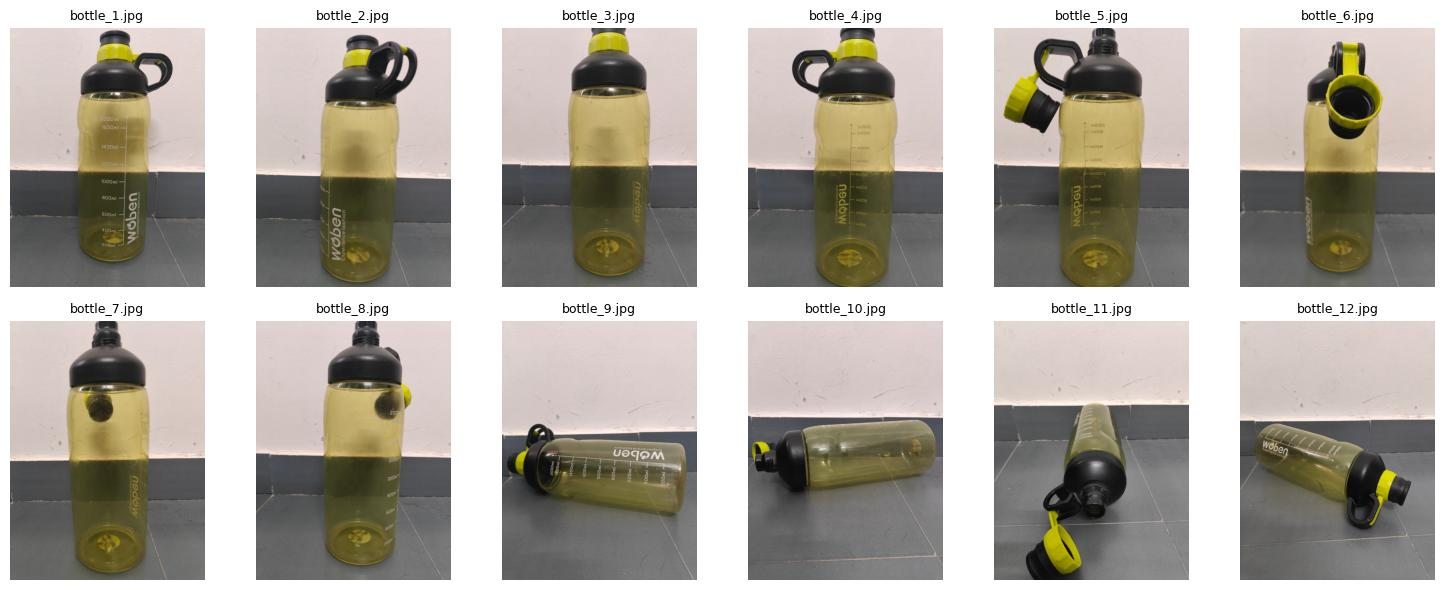

In [2]:
names, images = c3d.load_images("bottle_images.zip", max_side=640)
print(len(images), "views:", names)

fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for ax, name, img in zip(axes.ravel(), names, images):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(name, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. ORB keypoints + two descriptors for the same keypoints

In [3]:
keypoints, orb_des = c3d.detect_orb(images, n_features=3000)
model = c3d.ResNetFeatures().eval().to(device)
cnn_des = [c3d.cnn_descriptors(model, img, kp, device, upscale=2.0) for img, kp in zip(images, keypoints)]
print("keypoints per view:", [len(k) for k in keypoints])
print("ORB descriptor: 256-bit binary | CNN descriptor dim:", cnn_des[0].shape[1])

keypoints per view: [1784, 1217, 713, 1320, 1482, 692, 763, 1048, 1770, 750, 977, 1521]
ORB descriptor: 256-bit binary | CNN descriptor dim: 448


## 3. Match consecutive pairs and filter with RANSAC

The CNN ratio test compares the best match against the best candidate **more than 16 px away**. Neighbouring keypoints sample almost the same coarse feature-map cell, so a plain ratio test would wrongly reject them as ambiguous.

In [4]:
rows, cnn_inliers = [], {}
for a in range(len(images) - 1):
    b = a + 1
    orb_m = c3d.match_orb(orb_des[a], orb_des[b])
    cnn_m = c3d.match_cnn(cnn_des[a], cnn_des[b], keypoints[b], ratio=0.9, radius=16)
    orb_in = c3d.ransac_inliers(keypoints[a], keypoints[b], orb_m)
    cnn_in = c3d.ransac_inliers(keypoints[a], keypoints[b], cnn_m)
    cnn_inliers[(a, b)] = [m for m, k in zip(cnn_m, cnn_in) if k]
    rows.append((f"{a+1}-{b+1}", len(orb_m), int(orb_in.sum()), len(cnn_m), int(cnn_in.sum())))

print(f"{'pair':>6} | {'ORB matches':>11} {'inliers':>8} | {'CNN matches':>11} {'inliers':>8}")
for r in rows:
    print(f"{r[0]:>6} | {r[1]:>11} {r[2]:>8} | {r[3]:>11} {r[4]:>8}")
tot = np.array([r[1:] for r in rows]).sum(0)
print(f"{'total':>6} | {tot[0]:>11} {tot[1]:>8} | {tot[2]:>11} {tot[3]:>8}")
print(f"inlier ratio  ORB {tot[1]/tot[0]:.2f} | CNN {tot[3]/tot[2]:.2f}")

  pair | ORB matches  inliers | CNN matches  inliers
   1-2 |          82       58 |         265      183
   2-3 |          56       39 |         142       99
   3-4 |          73       52 |         199      133
   4-5 |         152      121 |         369      273
   5-6 |          29       14 |          73       49
   6-7 |          21       13 |          70       54
   7-8 |          48       36 |         120       90
   8-9 |          17       10 |          38       16
  9-10 |          50       32 |          72       60
 10-11 |          33       25 |          55       43
 11-12 |          55       42 |          91       75
 total |         616      442 |        1494     1075
inlier ratio  ORB 0.72 | CNN 0.72


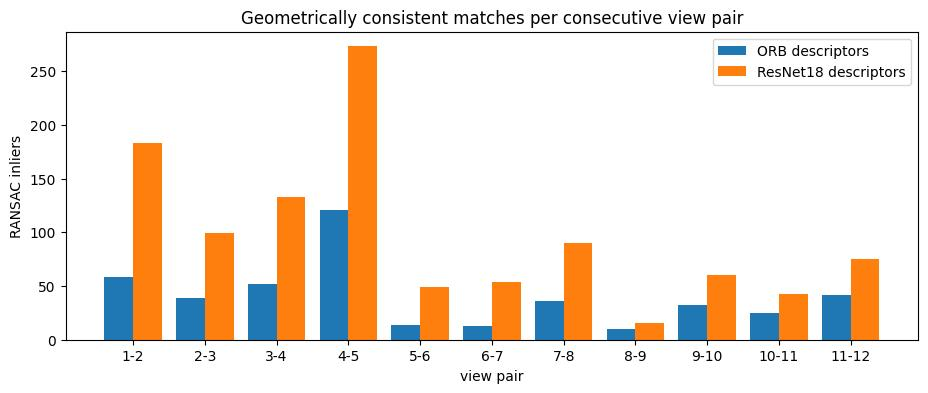

In [5]:
pairs = [r[0] for r in rows]
x = np.arange(len(pairs))
plt.figure(figsize=(11, 4))
plt.bar(x - 0.2, [r[2] for r in rows], 0.4, label="ORB descriptors")
plt.bar(x + 0.2, [r[4] for r in rows], 0.4, label="ResNet18 descriptors")
plt.xticks(x, pairs); plt.xlabel("view pair"); plt.ylabel("RANSAC inliers")
plt.title("Geometrically consistent matches per consecutive view pair"); plt.legend(); plt.show()

## 4. Inspect the CNN matches for the best pair

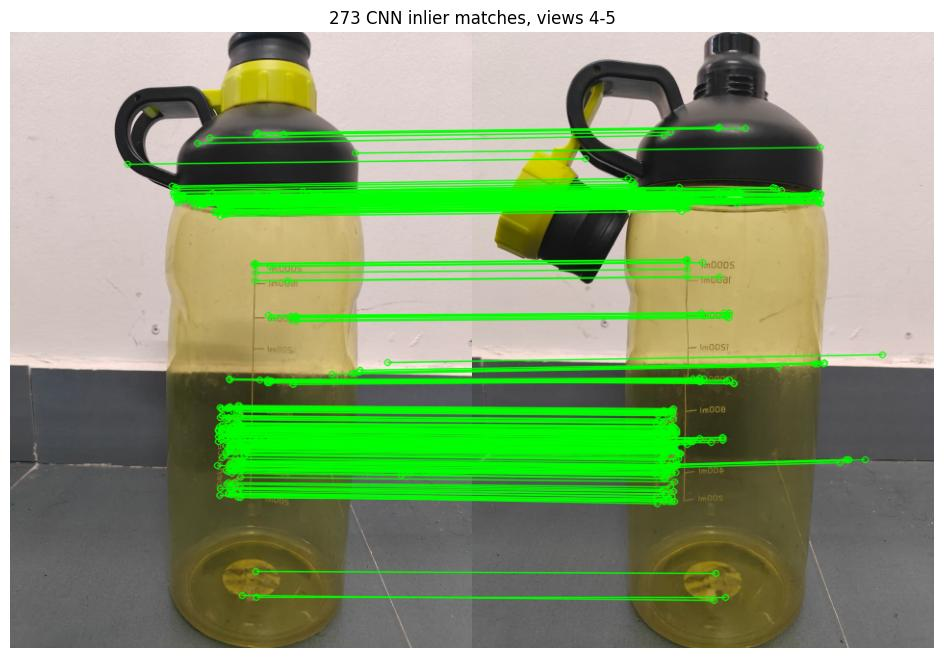

In [6]:
a, b = max(cnn_inliers, key=lambda k: len(cnn_inliers[k]))
vis = cv2.drawMatches(images[a], keypoints[a], images[b], keypoints[b],
                      [cv2.DMatch(i, j, 0) for i, j in cnn_inliers[(a, b)]], None,
                      matchColor=(0, 255, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(12, 8)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title(f"{len(cnn_inliers[(a, b)])} CNN inlier matches, views {a+1}-{b+1}"); plt.show()

## 5. Two-view triangulation (sparse, up to scale)

The camera is uncalibrated, so the intrinsics are approximated (focal length ≈ 1.2 × image width). The essential matrix and relative pose are estimated from the inliers, and the matches are triangulated. The bottle is transparent and was repositioned by hand between shots, so treat the cloud as a **rough sparse approximation**, not a metric reconstruction.

220 points | estimated rotation 29.2 deg | median reprojection error 0.28 px


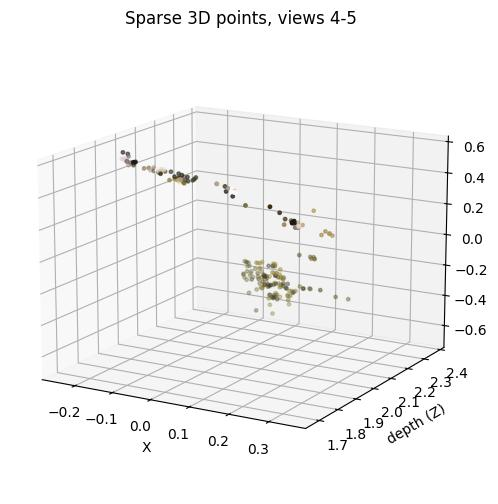

Interactive version saved to outputs/point_cloud.html


In [7]:
points, colors, angle, reproj = c3d.triangulate_pair(images[a], keypoints[a], keypoints[b], cnn_inliers[(a, b)])
print(f"{len(points)} points | estimated rotation {angle:.1f} deg | median reprojection error {reproj:.2f} px")

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
ax.scatter(points[:, 0], points[:, 2], -points[:, 1], c=colors / 255.0, s=6)
ax.set_xlabel("X"); ax.set_ylabel("depth (Z)"); ax.set_zlabel("Y"); ax.view_init(15, -60)
plt.title(f"Sparse 3D points, views {a+1}-{b+1}"); plt.show()

os.makedirs("outputs", exist_ok=True)
c3d.save_plotly(points, colors, "outputs/point_cloud.html", f"Sparse 3D points, views {a+1}-{b+1}")
print("Interactive version saved to outputs/point_cloud.html")